# Segmentación Semántica en Video con Arquitectura U-Net
**Duración:** 2 horas y 30 minutos (150 minutos) | **Modalidad:** Individual

### Reglas e Instrucciones Generales
1. **Prohibido el uso de librerías de segmentación preconstruidas** (`segmentation_models_pytorch`, `monai`, `torchvision.models.segmentation`).
2. Todos tus hiperparámetros, cortes de video y dimensiones de red dependen estrictamente de tu variable **`SEED`** (últimos 3 dígitos de tu matrícula).
3. No modifiques los bloques de verificación (`assert`) ni las firmas de las funciones.
4. **Entrada de video:** Coloca tu archivo de video guardado en la misma carpeta con el nombre `video_entrada.mp4`. Si no dispones de uno, la celda de respaldo creará automáticamente un video médico sintético de ultrasonido en movimiento.

---
### 📚 Material de Consulta Permitido
Puedes consultar únicamente la documentación oficial de PyTorch/OpenCV/Matplotlib y los siguientes recursos seleccionados:

**Guías Escritas y Código de Referencia (PyTorch):**
- [Tutorial U-Net en PyTorch: Construye un Modelo de Segmentación (Medium)](https://medium.com/image-segmentation-tutorials/unet-pytorch-tutorial-build-a-segmentation-model-eb62e8525b75)
- [Implementación de U-Net en 60 Líneas de Código en PyTorch (Aman Arora)](https://amaarora.github.io/posts/2020-09-13-unet.html)
- [Implementación de Dice Loss en PyTorch (Medium)](https://medium.com/data-scientists-diary/implementation-of-dice-loss-vision-pytorch-7eef1e438f68)
- [Combinación de BCE Loss y Dice Loss en PyTorch (Kyosuke Fukumoto)](https://kyosukefukumoto.com/164-combining-losses/)

**Videos Explicativos (Arquitectura y Skip Connections):**
- [U-Net Image Segmentation the Basics (From Scratch!) - YouTube](https://www.youtube.com/watch?v=ZoOuNv8TXLs)
- [The U-Net (actually) explained in 10 minutes - YouTube](https://www.youtube.com/watch?v=NhdzGfB1q74)
- [Segmentación semántica de imágenes usando U-net (Español) - YouTube](https://www.youtube.com/watch?v=3v7sYqigeSc)

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# ==========================================================
# PASO 0: CONFIGURACIÓN DE IDENTIDAD (15 min)
# ==========================================================
SEED = 425

assert isinstance(SEED, int) and 0 <= SEED <= 999, "Debes asignar un entero de 3 dígitos a SEED."

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hiperparámetros individuales derivados de tu matrícula
OFFSET = SEED % 30
UMBRAL = 90 + (SEED % 50)
BASE_CH = 16 if (SEED % 2 == 0) else 24
ALPHA = round(0.3 + (SEED % 6) * 0.1, 2)

print(f"Dispositivo: {device} | SEED: {SEED}")
print(f"OFFSET: {OFFSET} frames | UMBRAL: {UMBRAL} | BASE_CH: {BASE_CH} | ALPHA: {ALPHA}")

Dispositivo: cuda | SEED: 425
OFFSET: 5 frames | UMBRAL: 115 | BASE_CH: 24 | ALPHA: 0.8


In [2]:
# ==========================================================
# RESPUESTO DE VIDEO LOCAL (Ejecutar solo si no tienes un .mp4 propio)
# ==========================================================
def generar_video_respaldo(ruta="/content/13722965_2160_3840_30fps.mp4", total_frames=160, size=128):
    if os.path.exists(ruta):
        print(f"Archivo '{ruta}' detectado en disco. Se usará este video.")
        return
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(ruta, fourcc, 20.0, (size, size), isColor=False)
    rng = np.random.default_rng(42)
    for t in range(total_frames):
        frame = rng.normal(45, 12, (size, size)).astype(np.float32)
        cx = int(64 + 22 * np.sin(t * 0.08))
        cy = int(64 + 18 * np.cos(t * 0.06))
        rx = int(22 + 4 * np.sin(t * 0.12))
        ry = int(16 + 3 * np.cos(t * 0.10))
        mask_temp = np.zeros((size, size), dtype=np.uint8)
        cv2.ellipse(mask_temp, (cx, cy), (rx, ry), t * 1.5, 0, 360, 255, -1)
        mask_blur = cv2.GaussianBlur(mask_temp.astype(np.float32), (7, 7), 0)
        frame = np.clip(frame + (mask_blur / 255.0) * 145.0, 0, 255).astype(np.uint8)
        out.write(frame)
    out.release()
    print(f"Video sintético generado correctamente en '{ruta}' ({total_frames} fotogramas).")

generar_video_respaldo("/content/13722965_2160_3840_30fps.mp4")

Archivo '/content/13722965_2160_3840_30fps.mp4' detectado en disco. Se usará este video.


### Parte 1: Lectura de Video y Generación de Máscaras Semánticas (25 min)
Completa la función `cargar_dataset_video` para:
1. Abrir `video_entrada.mp4` con `cv2.VideoCapture`.
2. Saltar los primeros `OFFSET` fotogramas y leer exactamente **120 fotogramas** consecutivos.
3. Convertir cada fotograma a escala de grises y redimensionarlo a **128 × 128** píxeles.
4. Generar su máscara binaria `Y` aplicando el umbral `UMBRAL` (`frame >= UMBRAL`) y una operación morfológica de cierre (`cv2.morphologyEx(..., cv2.MORPH_CLOSE, kernel)`) con un kernel de 5 × 5.
5. Normalizar las imágenes `X` al rango `[0.0, 1.0]` con forma `(120, 1, 128, 128)` y máscaras `Y` en `{0.0, 1.0}` con forma `(120, 1, 128, 128)`.

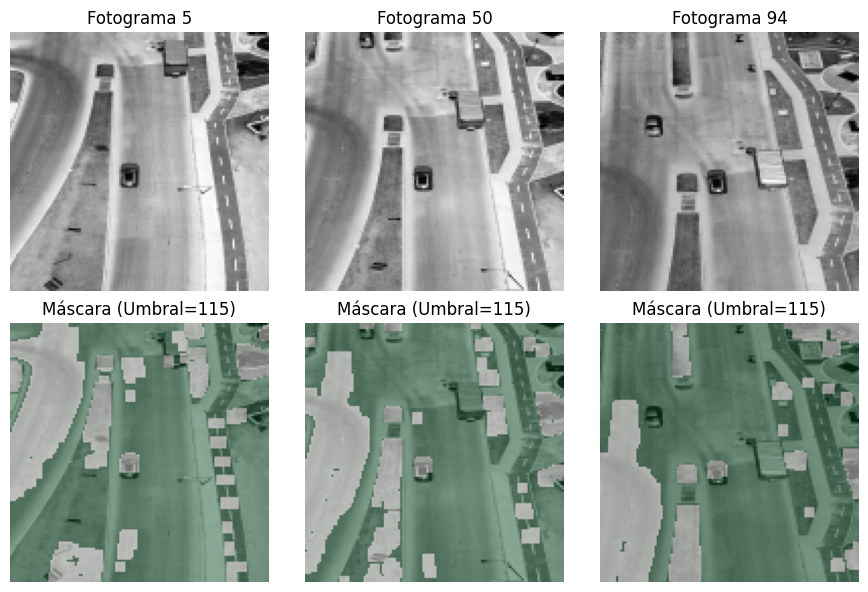

In [3]:
def cargar_dataset_video(ruta_video, offset, umbral, num_frames=120, img_size=128):
    cap = cv2.VideoCapture(ruta_video)
    assert cap.isOpened(), f"No se pudo abrir el video: {ruta_video}"

    X_list, Y_list = [], []
    kernel = np.ones((5, 5), np.uint8)

    # Avanzar 'offset' fotogramas
    for _ in range(offset):
        ret, _ = cap.read()
        if not ret:
            break

    # Extraer 'num_frames' fotogramas consecutivos
    while len(X_list) < num_frames:
        ret, frame = cap.read()
        if not ret:
            break

        # Convertir a escala de grises si tiene 3 canales
        if len(frame.shape) == 3:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        else:
            gray = frame

        # Redimensionar a (img_size, img_size)
        resized = cv2.resize(gray, (img_size, img_size), interpolation=cv2.INTER_AREA)

        # Crear máscara binaria uint8 (0 o 255) donde pixel >= umbral
        mask = np.where(resized >= umbral, 255, 0).astype(np.uint8)

        # Operación morfológica de cierre con kernel 5x5
        mask_closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

        # Normalizar X a [0, 1] float32 y Y a {0.0, 1.0} float32
        X_list.append(resized.astype(np.float32) / 255.0)
        Y_list.append((mask_closed > 0).astype(np.float32))

    cap.release()
    X = np.array(X_list, dtype=np.float32)[:, None, :, :]
    Y = np.array(Y_list, dtype=np.float32)[:, None, :, :]
    return X, Y

X_all, Y_all = cargar_dataset_video("/content/13722965_2160_3840_30fps.mp4", OFFSET, UMBRAL)

# Verificaciones obligatorias
assert X_all.shape == (120, 1, 128, 128), f"Forma incorrecta de X: {X_all.shape}"
assert Y_all.shape == (120, 1, 128, 128), f"Forma incorrecta de Y: {Y_all.shape}"
assert set(np.unique(Y_all)).issubset({0.0, 1.0}), "La máscara Y debe ser estrictamente binaria (0.0 y 1.0)."

# División temporal (sin mezclar): 90 entrenamiento, 30 validación
X_train, Y_train = torch.tensor(X_all[:90]), torch.tensor(Y_all[:90])
X_val, Y_val = torch.tensor(X_all[90:]), torch.tensor(Y_all[90:])

train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=10, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=10, shuffle=False)

# Visualización de 3 fotogramas y sus máscaras
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for idx, frame_idx in enumerate([0, 45, 89]):
    axes[0, idx].imshow(X_all[frame_idx, 0], cmap='gray')
    axes[0, idx].set_title(f"Fotograma {frame_idx + OFFSET}")
    axes[0, idx].axis('off')
    axes[1, idx].imshow(X_all[frame_idx, 0], cmap='gray')
    axes[1, idx].imshow(Y_all[frame_idx, 0], cmap='Greens', alpha=0.45)
    axes[1, idx].set_title(f"Máscara (Umbral={UMBRAL})")
    axes[1, idx].axis('off')
plt.tight_layout()
plt.show()

### Parte 2: Arquitectura U-Net Manual con Interruptor de *Skip Connections* (45 min)
Implementa `DoubleConv` y `UNetPersonalizada` desde cero:
- **`DoubleConv(in_ch, out_ch)`**: Dos bloques secuenciales de `Conv2d(kernel_size=3, padding=1)` + `BatchNorm2d` + `ReLU(inplace=True)`.
- **Encoder (3 niveles):**
  - `enc1`: `1 -> BASE_CH` (128×128) -> `MaxPool2d(2)` (64×64)
  - `enc2`: `BASE_CH -> BASE_CH*2` (64×64) -> `MaxPool2d(2)` (32×32)
  - `enc3`: `BASE_CH*2 -> BASE_CH*4` (32×32) -> `MaxPool2d(2)` (16×16)
- **Bottleneck:** `BASE_CH*4 -> BASE_CH*8` (16×16)
- **Decoder (3 niveles):**
  - Cada etapa realiza `ConvTranspose2d(kernel_size=2, stride=2)`, concatena (`torch.cat(..., dim=1)`) la *skip connection* correspondiente y aplica `DoubleConv`.
  - **Interruptor de sabotaje (`use_skip=True`):** Si `use_skip=False`, antes de concatenar cada *skip connection* (`s3, s2, s1`), debes reemplazarla por `torch.zeros_like(s_i)`.
- **Salida:** `Conv2d(BASE_CH, 1, kernel_size=1)` devolviendo *logits* sin `Sigmoid`.

In [4]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class UNetPersonalizada(nn.Module):
    def __init__(self, base_ch=BASE_CH, use_skip=True):
        super().__init__()
        self.use_skip = use_skip

        # Encoder
        self.enc1 = DoubleConv(1, base_ch)
        self.enc2 = DoubleConv(base_ch, base_ch * 2)
        self.enc3 = DoubleConv(base_ch * 2, base_ch * 4)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck (16x16)
        self.bottleneck = DoubleConv(base_ch * 4, base_ch * 8)

        # Decoder
        self.up3 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base_ch * 8, base_ch * 4)

        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_ch * 4, base_ch * 2)

        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_ch * 2, base_ch)

        # Salida (logits crudos)
        self.out_conv = nn.Conv2d(base_ch, 1, kernel_size=1)

    def forward(self, x):
        # Contracción
        s1 = self.enc1(x)              # 128x128
        p1 = self.pool(s1)             # 64x64

        s2 = self.enc2(p1)             # 64x64
        p2 = self.pool(s2)             # 32x32

        s3 = self.enc3(p2)             # 32x32
        p3 = self.pool(s3)             # 16x16

        # Cuello de botella
        b = self.bottleneck(p3)        # 16x16

        # Interruptor de sabotaje
        if not self.use_skip:
            s1 = torch.zeros_like(s1)
            s2 = torch.zeros_like(s2)
            s3 = torch.zeros_like(s3)

        # Expansión
        d3 = self.up3(b)               # 32x32
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)              # 64x64
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)              # 128x128
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

# Prueba de dimensiones
modelo_test = UNetPersonalizada(base_ch=BASE_CH, use_skip=True).to(device)
dummy_in = torch.randn(2, 1, 128, 128, device=device)
dummy_out = modelo_test(dummy_in)
assert dummy_out.shape == (2, 1, 128, 128), f"Salida inesperada de U-Net: {dummy_out.shape}"
print(f"U-Net verificada correctamente con BASE_CH={BASE_CH}. Parámetros: {sum(p.numel() for p in modelo_test.parameters()):,}")

U-Net verificada correctamente con BASE_CH=24. Parámetros: 1,084,249


### Parte 3: Pérdida Híbrida (BCE + Dice) y Entrenamiento (30 min)
Programa:
1. `dice_coefficient(logits, targets, smooth=1e-6)`: aplica `torch.sigmoid(logits)` y calcula el coeficiente de Dice promedio del lote.
2. `hybrid_loss(logits, targets, alpha=ALPHA)`: retorna `alpha * BCEWithLogitsLoss()(logits, targets) + (1 - alpha) * (1 - dice_coefficient(logits, targets))`.
3. Entrena `unet_completa` durante **20 épocas** con `Adam(lr=1e-3)`.

Época [01/20] - Train Loss: 0.4394 | Val Dice: 0.6253
Época [02/20] - Train Loss: 0.3254 | Val Dice: 0.7005
Época [03/20] - Train Loss: 0.2884 | Val Dice: 0.7544
Época [04/20] - Train Loss: 0.2599 | Val Dice: 0.7901
Época [05/20] - Train Loss: 0.2350 | Val Dice: 0.8067
Época [06/20] - Train Loss: 0.2129 | Val Dice: 0.8317
Época [07/20] - Train Loss: 0.1938 | Val Dice: 0.8517
Época [08/20] - Train Loss: 0.1764 | Val Dice: 0.8688
Época [09/20] - Train Loss: 0.1614 | Val Dice: 0.8828
Época [10/20] - Train Loss: 0.1482 | Val Dice: 0.8979
Época [11/20] - Train Loss: 0.1355 | Val Dice: 0.9088
Época [12/20] - Train Loss: 0.1257 | Val Dice: 0.9147
Época [13/20] - Train Loss: 0.1150 | Val Dice: 0.9159
Época [14/20] - Train Loss: 0.1063 | Val Dice: 0.9273
Época [15/20] - Train Loss: 0.0988 | Val Dice: 0.9290
Época [16/20] - Train Loss: 0.0919 | Val Dice: 0.9344
Época [17/20] - Train Loss: 0.0851 | Val Dice: 0.9390
Época [18/20] - Train Loss: 0.0799 | Val Dice: 0.9447
Época [19/20] - Train Loss: 

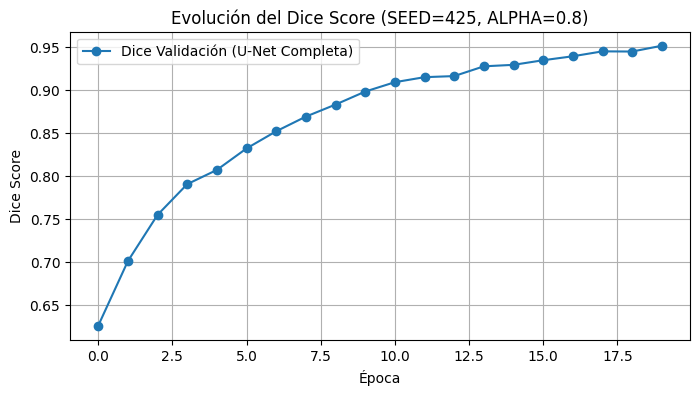

In [5]:
def dice_coefficient(logits, targets, smooth=1e-6):
    probs = torch.sigmoid(logits)
    # Aplanar por muestra dentro del batch: (B, -1)
    probs_flat = probs.view(probs.size(0), -1)
    targets_flat = targets.view(targets.size(0), -1)

    intersection = (probs_flat * targets_flat).sum(dim=1)
    union = probs_flat.sum(dim=1) + targets_flat.sum(dim=1)

    dice = (2.0 * intersection + smooth) / (union + smooth)
    return dice.mean()

def hybrid_loss(logits, targets, alpha=ALPHA):
    bce = nn.BCEWithLogitsLoss()(logits, targets)
    dice_loss = 1.0 - dice_coefficient(logits, targets)
    return alpha * bce + (1.0 - alpha) * dice_loss

def entrenar_modelo(model, train_loader, val_loader, epochs=20, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    historial = {'train_loss': [], 'val_dice': []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            logits = model(x_batch)
            loss = hybrid_loss(logits, y_batch, alpha=ALPHA)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x_batch.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        # Evaluación en validación
        model.eval()
        val_dice_total = 0.0
        with torch.no_grad():
            for x_val_b, y_val_b in val_loader:
                x_val_b, y_val_b = x_val_b.to(device), y_val_b.to(device)
                val_logits = model(x_val_b)
                batch_dice = dice_coefficient(val_logits, y_val_b)
                val_dice_total += batch_dice.item() * x_val_b.size(0)

        epoch_val_dice = val_dice_total / len(val_loader.dataset)
        historial['train_loss'].append(epoch_loss)
        historial['val_dice'].append(epoch_val_dice)

        print(f"Época [{epoch+1:02d}/{epochs:02d}] - Train Loss: {epoch_loss:.4f} | Val Dice: {epoch_val_dice:.4f}")

    return historial

torch.manual_seed(SEED)
unet_completa = UNetPersonalizada(base_ch=BASE_CH, use_skip=True).to(device)
hist_completa = entrenar_modelo(unet_completa, train_loader, val_loader, epochs=20)

plt.figure(figsize=(8, 4))
plt.plot(hist_completa['val_dice'], marker='o', label='Dice Validación (U-Net Completa)')
plt.title(f'Evolución del Dice Score (SEED={SEED}, ALPHA={ALPHA})')
plt.xlabel('Época')
plt.ylabel('Dice Score')
plt.grid(True)
plt.legend()
plt.show()

### Parte 4: El Sabotaje a las *Skip Connections* e Inferencia en Video (35 min)
1. Entrena `unet_sin_skip = UNetPersonalizada(base_ch=BASE_CH, use_skip=False)` durante **20 épocas**.
2. Genera la figura comparativa lado a lado sobre el fotograma de validación índice `15` (fotograma 105 del subconjunto) mostrando: Original, Ground Truth, U-Net Completa (con Dice Score) y U-Net sin Skip Connections (con Dice Score).
3. Exporta los 30 fotogramas de validación segmentados con `unet_completa` al archivo `resultado_segmentado_{SEED}.mp4` superponiendo la máscara predicha en color verde.

Época [01/20] - Train Loss: 0.4947 | Val Dice: 0.6028
Época [02/20] - Train Loss: 0.3438 | Val Dice: 0.6470
Época [03/20] - Train Loss: 0.2995 | Val Dice: 0.7308
Época [04/20] - Train Loss: 0.2684 | Val Dice: 0.7964
Época [05/20] - Train Loss: 0.2426 | Val Dice: 0.8231
Época [06/20] - Train Loss: 0.2192 | Val Dice: 0.8460
Época [07/20] - Train Loss: 0.1999 | Val Dice: 0.8477
Época [08/20] - Train Loss: 0.1830 | Val Dice: 0.8715
Época [09/20] - Train Loss: 0.1675 | Val Dice: 0.8715
Época [10/20] - Train Loss: 0.1538 | Val Dice: 0.8878
Época [11/20] - Train Loss: 0.1420 | Val Dice: 0.9042
Época [12/20] - Train Loss: 0.1303 | Val Dice: 0.9047
Época [13/20] - Train Loss: 0.1203 | Val Dice: 0.9136
Época [14/20] - Train Loss: 0.1124 | Val Dice: 0.9222
Época [15/20] - Train Loss: 0.1046 | Val Dice: 0.9316
Época [16/20] - Train Loss: 0.0997 | Val Dice: 0.9308
Época [17/20] - Train Loss: 0.0929 | Val Dice: 0.9377
Época [18/20] - Train Loss: 0.0845 | Val Dice: 0.9361
Época [19/20] - Train Loss: 

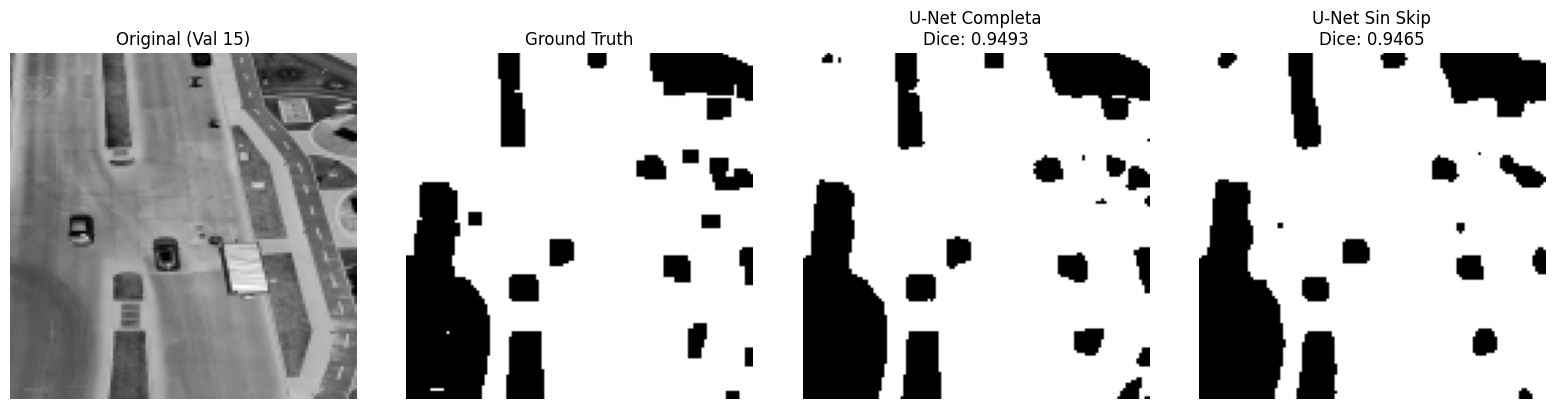

Video segmentado exportado exitosamente en: 'resultado_segmentado_425.mp4'


In [6]:
torch.manual_seed(SEED)
unet_sin_skip = UNetPersonalizada(base_ch=BASE_CH, use_skip=False).to(device)
hist_sin_skip = entrenar_modelo(unet_sin_skip, train_loader, val_loader, epochs=20)

# 1) Comparativa Forense sobre el fotograma de validación índice 15
unet_completa.eval()
unet_sin_skip.eval()

sample_x = X_val[15:16].to(device)
sample_y = Y_val[15:16].to(device)

with torch.no_grad():
    logits_comp = unet_completa(sample_x)
    logits_sin = unet_sin_skip(sample_x)

    dice_comp = dice_coefficient(logits_comp, sample_y).item()
    dice_sin = dice_coefficient(logits_sin, sample_y).item()

    pred_comp = (torch.sigmoid(logits_comp) > 0.5).float().cpu().numpy()[0, 0]
    pred_sin = (torch.sigmoid(logits_sin) > 0.5).float().cpu().numpy()[0, 0]

orig_img = sample_x.cpu().numpy()[0, 0]
gt_img = sample_y.cpu().numpy()[0, 0]

print(f"\n--- RESULTADOS COMPARATIVA FORENSE (Frame Val 15) ---")
print(f"Dice Score U-Net Completa: {dice_comp:.4f}")
print(f"Dice Score U-Net Sin Skip: {dice_sin:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(orig_img, cmap='gray')
axes[0].set_title("Original (Val 15)")
axes[0].axis('off')

axes[1].imshow(gt_img, cmap='gray')
axes[1].set_title("Ground Truth")
axes[1].axis('off')

axes[2].imshow(pred_comp, cmap='gray')
axes[2].set_title(f"U-Net Completa\nDice: {dice_comp:.4f}")
axes[2].axis('off')

axes[3].imshow(pred_sin, cmap='gray')
axes[3].set_title(f"U-Net Sin Skip\nDice: {dice_sin:.4f}")
axes[3].axis('off')

plt.tight_layout()
plt.show()

# 2) Exportación de Video Segmentado (30 fotogramas de validación)
output_filename = f"resultado_segmentado_{SEED}.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_video = cv2.VideoWriter(output_filename, fourcc, 10.0, (128, 128), isColor=True)

with torch.no_grad():
    val_logits_all = unet_completa(X_val.to(device))
    val_preds_all = (torch.sigmoid(val_logits_all) > 0.5).cpu().numpy()[:, 0]

for i in range(len(X_val)):
    # Convertir fotograma gris [0,1] a BGR uint8 [0,255]
    frame_gray = (X_val[i, 0].numpy() * 255).astype(np.uint8)
    frame_bgr = cv2.cvtColor(frame_gray, cv2.COLOR_GRAY2BGR)

    # Crear capa verde donde haya predicción positiva
    mask_bool = val_preds_all[i] > 0.5
    overlay = frame_bgr.copy()
    overlay[mask_bool] = [0, 255, 0]  # Verde en formato BGR

    # Mezcla semitransparente (alpha blending)
    blended = cv2.addWeighted(frame_bgr, 0.65, overlay, 0.35, 0)
    out_video.write(blended)

out_video.release()
print(f"Video segmentado exportado exitosamente en: '{output_filename}'")

### Análisis Forense Obligatorio (Máximo 120 palabras)
**Instrucción:** Explica por qué la U-Net sin *skip connections* pierde nitidez y precisión en los contornos de la segmentación aunque logre localizar aproximadamente el objeto. **Debes citar explícitamente los dos valores de Dice Score obtenidos en tu experimento.**

> *Escribe tu análisis aquí...*